Tarea 4

In [2]:
# Nombre: Sofía Rojas
# RUT: 22.532.158-2

In [3]:
# # # librerias y semilla
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import string
rng = np.random.default_rng(seed=1209)

In [4]:
# # # PT. 1 // Generación del catálogo
N_e = 100

# Radio estelar
R_e = rng.uniform(0.5, 5.0, N_e)
# Distancia (pc)
d = rng.uniform(50,500,N_e)
# Temperatura efectiva
T = rng.uniform(3000, 10000, N_e)

# # # Creación del DataFrame

catalogo = pd.DataFrame(
    {'ID Estrella': [f'Estrella{i+1}' for i in range(N_e)],
    'Radio (R⊙)': R_e, 
    'Distancia (pc)': d, 
    'Temperatura efectiva (K)': T})

In [5]:
# # # 10 primeras filas del catálogo
print(" # # # 10 primeras filas del catálogo # # # ")
catalogo.iloc[:10]

 # # # 10 primeras filas del catálogo # # # 


,ID Estrella,Radio (R⊙),Distancia (pc),Temperatura efectiva (K)
0,Estrella1,1.904190,238.805840,9917.813905
1,Estrella2,1.525155,139.584190,3450.330294
2,Estrella3,4.779242,134.520191,5485.617567
3,Estrella4,1.536851,230.943816,3221.074541
4,Estrella5,1.199181,311.453576,8745.135425
5,Estrella6,2.593404,106.851443,3201.934711
6,Estrella7,1.036823,121.476532,3508.363401
7,Estrella8,4.191191,308.657889,9947.487995
8,Estrella9,3.398254,158.033426,8489.089564
9,Estrella10,3.130578,441.356657,6798.512544


In [6]:
# # # Estadísticas Descriptivas del catalógo
print(" # # # Estadísticas Descriptivas del catalógo # # # ")
catalogo.describe()

 # # # Estadísticas Descriptivas del catalógo # # # 


,Radio (R⊙),Distancia (pc),Temperatura efectiva (K)
count,100.000000,100.000000,100.000000
mean,2.761465,254.535009,6544.742542
std,1.338262,114.453476,2080.944253
min,0.511743,53.034964,3135.608008
25%,1.596540,143.934585,4833.773644
50%,2.777936,257.631177,6586.761887
75%,3.870520,347.296851,8468.612947
max,4.920943,494.665989,9990.164769


In [7]:
# # # PT.2 // Calculo de flujo y luminosidad estelar 

# # # Constantes físicas
sigma_SB = 5.670e-8         # Constante de Stefan-Boltzmann [W / m ^ 2 K ^ 4]
R_sol = 6.957e8             # Radio solar [m]
L_sol = 3.828e26            # Luminosidad solar [W]
pc_to_m = 3.086e16          # Parsec a metros [m]

# # # Conversión de unidades
R_estelar = catalogo['Radio (R⊙)'] * R_sol
D_estelar = catalogo['Distancia (pc)'] * pc_to_m
T_eff = catalogo['Temperatura efectiva (K)']

# # # Luminosidad estelar
Lum = 4 * np.pi * (R_estelar ** 2) * sigma_SB * (T_eff ** 4)  

In [8]:
# # # a) Luminosidad de cada estrella en luminosidades solares (L⊙)
Luminosidades = Lum / L_sol # Dividimos por luminosidades solares para obtener el resultado final

In [15]:
# # # b) Flujo observado de cada estrella
Flujo = Lum / (4 * np.pi * (D_estelar ** 2))

In [16]:
# # # c) Incorporamos nuevas columnas
catalogo['Luminosidad (L⊙)'] = Luminosidades
catalogo['Flujo'] = Flujo

In [17]:
catalogo.describe() # Comprobamos que funcione

,Radio (R⊙),Distancia (pc),Temperatura efectiva (K),Luminosidad (L⊙),Flujo
count,100.000000,100.000000,100.000000,100.000000,1.000000e+02
mean,2.761465,254.535009,6544.742542,23.751381,2.768292e-11
std,1.338262,114.453476,2080.944253,31.467362,7.903432e-11
min,0.511743,53.034964,3135.608008,0.043070,7.936328e-15
25%,1.596540,143.934585,4833.773644,1.684179,1.313941e-12
50%,2.777936,257.631177,6586.761887,8.637559,4.108419e-12
75%,3.870520,347.296851,8468.612947,36.775807,1.899611e-11
max,4.920943,494.665989,9990.164769,154.950696,5.336771e-10


In [18]:
# # # d) Mayor y menor luminosidades, flujos

Max_l = catalogo.loc[catalogo['Luminosidad (L⊙)'].idxmax()]
Min_l = catalogo.loc[catalogo['Luminosidad (L⊙)'].idxmin()]
Max_f = catalogo.loc[catalogo['Flujo'].idxmax()]
Min_f = catalogo.loc[catalogo['Flujo'].idxmin()]

print("# # # Extremos # # #")
print(f'Máxima luminosidad      | ID: {Max_l['ID Estrella']} - Luminosidad = {Max_l['Luminosidad (L⊙)']}')
print(f'Mínima luminosidad      | ID: {Min_l['ID Estrella']} - Luminosidad = {Min_l['Luminosidad (L⊙)']}')
print(f'Máximo flujo observado  | ID: {Max_f['ID Estrella']} - Flujo: {Max_f['Flujo']} [ Wm ^ -2 ] ')
print(f'Mínimoo flujo observado | ID: {Min_f['ID Estrella']} - Flujo:  {Min_f['Flujo']} [ Wm ^ -2 ]')

# # # Extremos # # #
Máxima luminosidad      | ID: Estrella8 - Luminosidad = 154.9506955739651
Mínima luminosidad      | ID: Estrella36 - Luminosidad = 0.04306952803575909
Máximo flujo observado  | ID: Estrella76 - Flujo: 5.336771473228008e-10 [ Wm ^ -2 ] 
Mínimoo flujo observado | ID: Estrella36 - Flujo:  7.9363280742218e-15 [ Wm ^ -2 ]


In [19]:
# # # PT.3 / Clasificación de estrellas

# Límite de detección del telescopio [W m^-2]
F_lim = 2e-10

# (a) Columna de clasificación: Detectada si F >= F_lim, No detectada en caso contrario
catalogo["Clasificacion"] = np.where(catalogo["Flujo"] >= F_lim,"Detectada", "No detectada")

# (b) Número de estrellas en cada categoría
conteo = catalogo["Clasificacion"].value_counts()
print(conteo)

# (c) Porcentaje de estrellas detectadas
pct_det = 100 * (catalogo["Clasificacion"] == "Detectada").mean()
print(f"Porcentaje de estrellas detectadas: {pct_det} %")

# (d) Promedios por categoría: flujo, distancia y temperatura efectiva
resumen = catalogo.groupby("Clasificacion")[["Flujo", "Distancia (pc)", "Temperatura efectiva (K)"]].mean()
resumen

Clasificacion
No detectada    97
Detectada        3
Name: count, dtype: int64
Porcentaje de estrellas detectadas: 3.0 %


,Flujo,Distancia (pc),Temperatura efectiva (K)
Clasificacion,,,
Detectada,4.420040e-10,74.678526,8452.399585
No detectada,1.486887e-11,260.097581,6485.742840


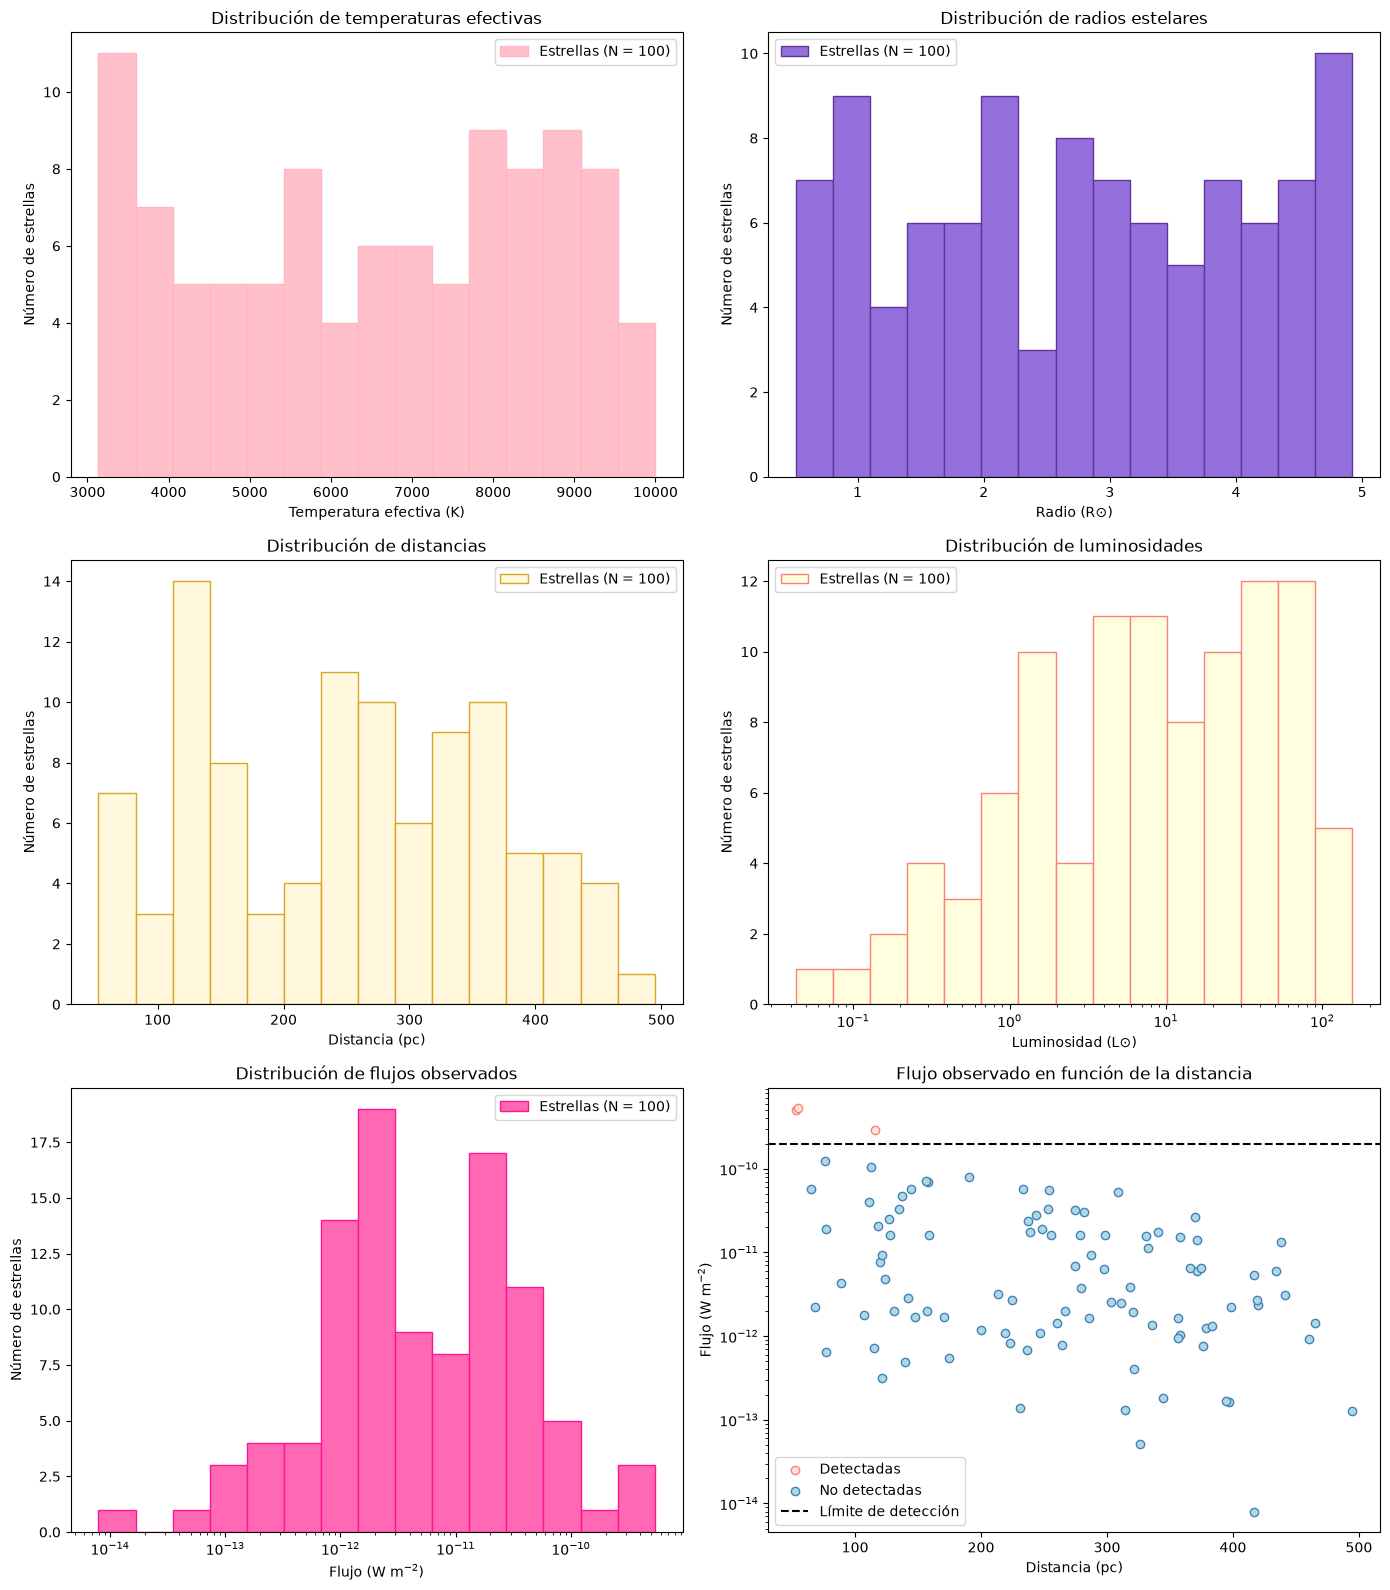

In [28]:
# # # PT.4 / Visualización de resultados

fig, axes = plt.subplots(3, 2, figsize=(14, 16))

# Máscaras para separar estrellas detectadas y no detectadas
detectada = catalogo['Clasificacion'] == 'Detectada'
no_detectada = ~detectada

# a) Histograma de temperaturas efectivas
axes[0, 0].hist(catalogo['Temperatura efectiva (K)'], bins=15, color='pink', edgecolor='lightpink', label='Estrellas (N = 100)')
axes[0, 0].set_title('Distribución de temperaturas efectivas')
axes[0, 0].set_xlabel('Temperatura efectiva (K)')
axes[0, 0].set_ylabel('Número de estrellas')
axes[0, 0].legend()

# b) Histograma de radios estelares
axes[0, 1].hist(catalogo['Radio (R⊙)'], bins=15, color='mediumpurple', edgecolor='rebeccapurple', label='Estrellas (N = 100)')
axes[0, 1].set_title('Distribución de radios estelares')
axes[0, 1].set_xlabel('Radio (R⊙)')
axes[0, 1].set_ylabel('Número de estrellas')
axes[0, 1].legend()

# c) Histograma de distancias
axes[1, 0].hist(catalogo['Distancia (pc)'], bins=15, color='cornsilk', edgecolor='goldenrod', label='Estrellas (N = 100)')
axes[1, 0].set_title('Distribución de distancias')
axes[1, 0].set_xlabel('Distancia (pc)')
axes[1, 0].set_ylabel('Número de estrellas')
axes[1, 0].legend()

# d) Histograma de luminosidades
# Como L abarca varios órdenes de magnitud, usamos bins en escala logarítmica
bins_L = np.logspace(np.log10(catalogo['Luminosidad (L⊙)'].min()), np.log10(catalogo['Luminosidad (L⊙)'].max()), 16)
axes[1, 1].hist(catalogo['Luminosidad (L⊙)'], bins=bins_L, color='lightyellow', edgecolor='salmon', label='Estrellas (N = 100)')
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('Distribución de luminosidades')
axes[1, 1].set_xlabel('Luminosidad (L⊙)')
axes[1, 1].set_ylabel('Número de estrellas')
axes[1, 1].legend()

# e) Histograma de flujos (misma idea: bins logarítmicos)
bins_F = np.logspace(np.log10(catalogo['Flujo'].min()), np.log10(catalogo['Flujo'].max()), 16)
axes[2, 0].hist(catalogo['Flujo'], bins=bins_F, color='hotpink', edgecolor='deeppink', label='Estrellas (N = 100)')
axes[2, 0].set_xscale('log')
axes[2, 0].set_title('Distribución de flujos observados')
axes[2, 0].set_xlabel('Flujo (W m$^{-2}$)')
axes[2, 0].set_ylabel('Número de estrellas')
axes[2, 0].legend()

# f) Dispersión: flujo vs distancia, detectadas y no detectadas con colores distintos
axes[2, 1].scatter(catalogo.loc[detectada, 'Distancia (pc)'], catalogo.loc[detectada, 'Flujo'], color='mistyrose', edgecolor='salmon', label='Detectadas')
axes[2, 1].scatter(catalogo.loc[no_detectada, 'Distancia (pc)'], catalogo.loc[no_detectada, 'Flujo'], color='lightblue', edgecolor='steelblue', label='No detectadas')
# Línea horizontal en el límite de detección
axes[2, 1].axhline(F_lim, color='black', linestyle='--', label='Límite de detección')
axes[2, 1].set_yscale('log')   # escala logarítmica en el flujo
axes[2, 1].set_title('Flujo observado en función de la distancia')
axes[2, 1].set_xlabel('Distancia (pc)')
axes[2, 1].set_ylabel('Flujo (W m$^{-2}$)')
axes[2, 1].legend()

plt.tight_layout()
plt.savefig('graficos.png', dpi=200)
plt.show()